# Hydra Reproduction — 30-Resample Protocol

**Goal:** check whether the published Hydra accuracies hold up when the paper's evaluation protocol is followed, and classify each discrepancy as *within expected variance* or *systematic*.

## Why this notebook exists
The earlier baseline (`shreed_hydra_baseline.ipynb`) ran Hydra **once, on the default train/test split**, and compared that single number with the published value. However, the published values in `hydra-authors-repo/results/results_ucr112_hydra.csv` are **means over 30 resamples** (paper §4.1). This is visible in the file itself: e.g. ACSF1 has 100 test cases, so a single run can only score a multiple of 0.01, yet the published accuracy is 0.806667. A single default-split run therefore cannot tell noise from a real discrepancy.

## Protocol (matched to the paper)
| Aspect | Paper | This notebook |
|---|---|---|
| Resamples | 30 (tsml resamples per Middlehurst et al.) | 30 — resample 0 = default split; resample *i* = `aeon` `stratified_resample_data(random_state=i)` (tsml convention) |
| Hydra | k = 8, g = 64, official code | official `hydra-authors-repo/code/hydra.py`, k = 8, g = 64, Hydra seed = resample id |
| Scaling | not described in the paper | `SparseScaler` from the official code |
| Classifier | ridge (alpha grid not reported in the paper) | `RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))` as in the authors' README |
| Compute | single CPU core | PyTorch and BLAS limited to 1 thread |

**Caveat:** the exact tsml resample indices were originally generated by the Java tsml code. `aeon` follows the same stratified procedure but is not guaranteed to produce identical splits, so we compare **distributions** (our 30-resample mean ± spread vs. the published 30-resample mean), not individual resamples.

## Datasets
15 datasets: the six used in the rest of the project (Coffee, ECG200, GunPoint, ItalyPowerDemand, TwoLeadECG, Wafer), plus nine harder datasets where the published accuracy is between 0.49 and 0.82, so that accuracy is not saturated at 100%.

## Outputs (`results/reproduction/`)
- `hydra_resample_runs.csv` — one row per (dataset, resample). The run cell **resumes**: completed runs are skipped.
- `hydra_vs_paper_summary.csv` — per-dataset comparison with the published means.
- `plots/hydra_resamples_vs_paper.png`

### Cell 1 — Imports

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util
import json
import platform
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from threadpoolctl import threadpool_limits

import aeon
import sklearn
from aeon.datasets import load_classification
from aeon.benchmarking.resampling import stratified_resample_data
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

### Cell 2 — Configuration and paths

The project root is found by searching upwards from the current directory, so the notebook works whether it is opened from the repository root or from `notebooks/`.

In [2]:
DATASETS = [
    # The six datasets used elsewhere in the project
    "Coffee", "ECG200", "GunPoint", "ItalyPowerDemand", "TwoLeadECG", "Wafer",
    # Harder datasets (published Hydra accuracy 0.49-0.82), small enough to run 30x on a laptop
    "Herring", "MiddlePhalanxTW", "Lightning2", "Lightning7", "Earthquakes",
    "MedicalImages", "Beef", "Adiac", "InsectWingbeatSound",
]
N_RESAMPLES = 30
K, G = 8, 64
BATCH_SIZE = 256
PAPER_ALPHAS = np.logspace(-3, 3, 10)   # authors' README setting
N_THREADS = 1                           # paper: single CPU core per dataset per resample

torch.set_num_threads(N_THREADS)

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (c for c in _candidates if (c / "hydra-authors-repo").is_dir() and (c / "results").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the hydra-time-series-project repository.")

HYDRA_SOURCE = PROJECT_ROOT / "hydra-authors-repo" / "code" / "hydra.py"
PAPER_RESULTS = PROJECT_ROOT / "hydra-authors-repo" / "results" / "results_ucr112_hydra.csv"
DATA_DIR = PROJECT_ROOT / "data" / "ucr_tsml"
OUT_DIR = PROJECT_ROOT / "results" / "reproduction"
PLOT_DIR = OUT_DIR / "plots"
RUNS_FILE = OUT_DIR / "hydra_resample_runs.csv"
SUMMARY_FILE = OUT_DIR / "hydra_vs_paper_summary.csv"

for d in (DATA_DIR, OUT_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.processor(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "pytorch": torch.__version__,
    "aeon": aeon.__version__,
    "torch_threads": torch.get_num_threads(),
}
with open(OUT_DIR / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

print("Project root:", PROJECT_ROOT)
print("Datasets:", len(DATASETS), "| resamples:", N_RESAMPLES, "| total runs:", len(DATASETS) * N_RESAMPLES)
for key, value in environment.items():
    print(f"{key:15}: {value}")

Project root: C:\Users\Aarti\Documents\GitHub\hydra-time-series-project
Datasets: 15 | resamples: 30 | total runs: 450
python         : 3.11.17
platform       : Windows-10-10.0.26200-SP0
processor      : Intel64 Family 6 Model 126 Stepping 5, GenuineIntel
numpy          : 2.3.5
pandas         : 3.0.6
scikit_learn   : 1.9.1
pytorch        : 2.14.1+cpu
aeon           : 1.6.0
torch_threads  : 1


### Cell 3 — Load the official Hydra implementation

In [3]:
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)

Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler
print("Loaded:", HYDRA_SOURCE)

Loaded: C:\Users\Aarti\Documents\GitHub\hydra-time-series-project\hydra-authors-repo\code\hydra.py


### Cell 4 — Data loading and resampling

Resample 0 is the predefined UCR train/test split. Resample *i* > 0 pools train and test and draws a new split with the same size and class distribution as the original training set (`stratified_resample_data(random_state=i)`).

In [4]:
import shutil

_default_splits = {}

def _load_both_splits(name):
    X_train, y_train = load_classification(name, split="train", extract_path=str(DATA_DIR), return_metadata=False)
    X_test, y_test = load_classification(name, split="test", extract_path=str(DATA_DIR), return_metadata=False)
    return X_train, y_train, X_test, y_test


def load_default_split(name):
    if name not in _default_splits:
        try:
            X_train, y_train, X_test, y_test = _load_both_splits(name)
        except OSError as exc:
            # A truncated download (e.g. an interrupted Wafer download) leaves a .ts file that
            # aeon cannot parse. Delete the cached copy and download it again once.
            print(f"{name}: could not parse cached files ({exc}); re-downloading.")
            shutil.rmtree(DATA_DIR / name, ignore_errors=True)
            X_train, y_train, X_test, y_test = _load_both_splits(name)
        _default_splits[name] = (
            np.asarray(X_train, dtype=np.float32), np.asarray(y_train).astype(str),
            np.asarray(X_test, dtype=np.float32), np.asarray(y_test).astype(str),
        )
    return _default_splits[name]


def get_resample(name, resample_id):
    X_train, y_train, X_test, y_test = load_default_split(name)
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    return stratified_resample_data(X_train, y_train, X_test, y_test, random_state=resample_id)

### Cell 5 — One Hydra run

Same pipeline as the authors' README: Hydra transform → `SparseScaler` → `RidgeClassifierCV`. Training time includes the training transform, scaling and the classifier fit (as in the published `time_training_seconds`); test time includes the test transform, scaling and prediction.

In [5]:
def run_one(name, resample_id):
    X_train, y_train, X_test, y_test = get_resample(name, resample_id)
    X_train_t = torch.as_tensor(np.ascontiguousarray(X_train), dtype=torch.float32)
    X_test_t = torch.as_tensor(np.ascontiguousarray(X_test), dtype=torch.float32)

    with threadpool_limits(limits=N_THREADS):
        start = perf_counter()
        transform = Hydra(X_train_t.shape[-1], k=K, g=G, seed=resample_id)
        with torch.inference_mode():
            Z_train = transform.batch(X_train_t, batch_size=BATCH_SIZE)
        scaler = SparseScaler()
        Z_train = scaler.fit_transform(Z_train).numpy()
        classifier = RidgeClassifierCV(alphas=PAPER_ALPHAS).fit(Z_train, y_train)
        train_seconds = perf_counter() - start

        start = perf_counter()
        with torch.inference_mode():
            Z_test = transform.batch(X_test_t, batch_size=BATCH_SIZE)
        Z_test = scaler.transform(Z_test).numpy()
        predictions = classifier.predict(Z_test)
        test_seconds = perf_counter() - start

    return {
        "dataset": name,
        "resample": resample_id,
        "hydra_seed": resample_id,
        "n_train": len(y_train),
        "n_test": len(y_test),
        "series_length": X_train.shape[-1],
        "n_features": Z_train.shape[1],
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "ridge_alpha": classifier.alpha_,
        "train_seconds": train_seconds,
        "test_seconds": test_seconds,
    }

### Cell 6 — Run all datasets × resamples (resumable)

Each finished run is appended to `hydra_resample_runs.csv` immediately, and runs already in the file are skipped. The full set (450 runs, single thread) takes roughly 30–60 minutes on a laptop; re-running this cell after that is instant.

In [6]:
done = set()
if RUNS_FILE.exists():
    previous = pd.read_csv(RUNS_FILE)
    done = set(zip(previous["dataset"], previous["resample"]))

for name in DATASETS:
    todo = [r for r in range(N_RESAMPLES) if (name, r) not in done]
    if not todo:
        print(f"{name:22} already complete")
        continue
    start = perf_counter()
    accs = []
    for r in todo:
        row = run_one(name, r)
        accs.append(row["accuracy"])
        pd.DataFrame([row]).to_csv(RUNS_FILE, mode="a", header=not RUNS_FILE.exists(), index=False)
    print(f"{name:22} ran {len(todo):2d} resamples | mean acc (new runs) = {np.mean(accs):.4f} | {perf_counter() - start:6.1f}s")

runs = pd.read_csv(RUNS_FILE)
runs = runs[runs["dataset"].isin(DATASETS) & (runs["resample"] < N_RESAMPLES)].copy()
print("\nRuns available:", len(runs))

Coffee                 already complete
ECG200                 already complete
GunPoint               already complete
ItalyPowerDemand       already complete
TwoLeadECG             already complete


Wafer                  ran 30 resamples | mean acc (new runs) = 1.0000 | 1287.2s


Herring                ran 30 resamples | mean acc (new runs) = 0.6438 |   78.5s


MiddlePhalanxTW        ran 30 resamples | mean acc (new runs) = 0.5548 |   46.7s


Lightning2             ran 30 resamples | mean acc (new runs) = 0.7383 |  131.5s


Lightning7             ran 30 resamples | mean acc (new runs) = 0.7785 |   77.5s


Earthquakes            ran 30 resamples | mean acc (new runs) = 0.7444 |  353.5s


MedicalImages          ran 30 resamples | mean acc (new runs) = 0.7654 |  108.1s


Beef                   ran 30 resamples | mean acc (new runs) = 0.7944 |   32.6s


Adiac                  ran 30 resamples | mean acc (new runs) = 0.8115 |  139.9s


InsectWingbeatSound    ran 30 resamples | mean acc (new runs) = 0.6638 |  653.9s

Runs available: 450


### Cell 7 — Per-dataset comparison with the published means

For each dataset we compare our 30-resample mean accuracy with the published 30-resample mean.

**Is a difference within expected variance?** Both numbers are means of 30 resamples, so (assuming the paper's spread across resamples is similar to ours) the standard error of their difference is approximately `SE_diff = sd · sqrt(2 / n)`, where `sd` is our standard deviation across resamples. We report `z = diff / SE_diff` and call the difference **within expected variance** if |z| ≤ 1.96 (≈ 95% level).

Because accuracy can only move in steps of `1 / n_test`, `sd` is floored at `1 / n_test`; otherwise a dataset where we score 100% on every resample would get a zero standard error.

In [7]:
paper = pd.read_csv(PAPER_RESULTS).rename(columns={
    "accuracy": "paper_accuracy",
    "time_training_seconds": "paper_train_seconds",
    "time_test_seconds": "paper_test_seconds",
})

summary = (
    runs.groupby("dataset")
    .agg(
        n_resamples=("accuracy", "size"),
        n_test=("n_test", "first"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        min_accuracy=("accuracy", "min"),
        max_accuracy=("accuracy", "max"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_train_seconds=("train_seconds", "mean"),
        mean_test_seconds=("test_seconds", "mean"),
    )
    .reset_index()
)
default_split = runs.loc[runs["resample"] == 0, ["dataset", "accuracy"]].rename(columns={"accuracy": "default_split_accuracy"})
summary = summary.merge(default_split, on="dataset").merge(paper, on="dataset", how="left")

sd_floored = np.maximum(summary["std_accuracy"].fillna(0), 1 / summary["n_test"])
summary["diff_pp"] = (summary["mean_accuracy"] - summary["paper_accuracy"]) * 100
summary["se_diff_pp"] = sd_floored * np.sqrt(2 / summary["n_resamples"]) * 100
summary["z"] = summary["diff_pp"] / summary["se_diff_pp"]
summary["verdict"] = np.where(summary["z"].abs() <= 1.96, "within expected variance", "outside expected variance")
summary["default_split_diff_pp"] = (summary["default_split_accuracy"] - summary["paper_accuracy"]) * 100
summary["paper_inside_our_range"] = summary["paper_accuracy"].between(summary["min_accuracy"], summary["max_accuracy"])

summary = summary.set_index("dataset").loc[DATASETS].reset_index()
summary.to_csv(SUMMARY_FILE, index=False)

display(summary[[
    "dataset", "paper_accuracy", "mean_accuracy", "std_accuracy", "diff_pp", "se_diff_pp", "z", "verdict",
    "default_split_accuracy", "default_split_diff_pp",
]].round(4))

,dataset,paper_accuracy,mean_accuracy,std_accuracy,diff_pp,se_diff_pp,z,verdict,default_split_accuracy,default_split_diff_pp
0,Coffee,0.9976,1.0000,0.0000,0.2381,0.9221,0.2582,within expected variance,1.0000,0.2381
1,ECG200,0.8947,0.8987,0.0250,0.4000,0.6459,0.6193,within expected variance,0.8700,-2.4667
2,GunPoint,0.9984,0.9971,0.0060,-0.1333,0.1721,-0.7743,within expected variance,1.0000,0.1556
3,ItalyPowerDemand,0.9616,0.9609,0.0065,-0.0680,0.1687,-0.4033,within expected variance,0.9660,0.4405
4,TwoLeadECG,0.9994,0.9989,0.0015,-0.0468,0.0380,-1.2320,within expected variance,0.9991,-0.0263
5,Wafer,1.0000,1.0000,0.0001,-0.0011,0.0042,-0.2689,within expected variance,1.0000,0.0032
6,Herring,0.6182,0.6438,0.0417,2.5521,1.0773,2.3689,outside expected variance,0.7500,13.1771
7,MiddlePhalanxTW,0.5578,0.5548,0.0261,-0.3030,0.6745,-0.4492,within expected variance,0.5390,-1.8831
8,Lightning2,0.7377,0.7383,0.0425,0.0546,1.0975,0.0498,within expected variance,0.7213,-1.6394
9,Lightning7,0.7831,0.7785,0.0436,-0.4566,1.1265,-0.4053,within expected variance,0.8082,2.5114


### Cell 8 — Is there a systematic difference across datasets?

A per-dataset test can flag individual outliers, but a **systematic** problem (e.g. our setup is consistently a little worse) shows up as differences that lean the same way across datasets. We test this with a Wilcoxon signed-rank test on the paired per-dataset accuracies (the same test the paper uses for its rankings). We run it twice: once with our 30-resample means, and once with only the default split, i.e. the protocol of the earlier baseline notebook.

In [8]:
def describe_differences(ours, label):
    diff = (ours - summary["paper_accuracy"]) * 100
    test = stats.wilcoxon(ours, summary["paper_accuracy"], zero_method="zsplit")
    print(f"{label}")
    print(f"  mean diff   : {diff.mean():+.2f} pp | median diff: {diff.median():+.2f} pp | mean |diff|: {diff.abs().mean():.2f} pp")
    print(f"  higher / tie / lower than paper: {(diff > 0).sum()} / {(diff == 0).sum()} / {(diff < 0).sum()}")
    print(f"  Wilcoxon signed-rank p = {test.pvalue:.3f}\n")

describe_differences(summary["mean_accuracy"], "30-resample mean vs paper")
describe_differences(summary["default_split_accuracy"], "Default split only vs paper (earlier protocol)")

counts = summary["verdict"].value_counts()
print("Per-dataset verdicts (30-resample protocol):")
print(counts.to_string())
print("\nPublished mean inside our min-max range across 30 resamples:",
      f"{summary['paper_inside_our_range'].sum()} / {len(summary)}")

30-resample mean vs paper
  mean diff   : +0.06 pp | median diff: -0.05 pp | mean |diff|: 0.44 pp
  higher / tie / lower than paper: 6 / 0 / 9
  Wilcoxon signed-rank p = 0.639

Default split only vs paper (earlier protocol)
  mean diff   : +0.87 pp | median diff: +0.16 pp | mean |diff|: 1.86 pp
  higher / tie / lower than paper: 9 / 0 / 6
  Wilcoxon signed-rank p = 0.639

Per-dataset verdicts (30-resample protocol):
verdict
within expected variance     14
outside expected variance     1

Published mean inside our min-max range across 30 resamples: 14 / 15


### Cell 9 — Plot: our 30 resamples vs the published mean

C:\Users\Aarti\AppData\Local\Temp\ipykernel_2792\2617728435.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, widths=0.6, showfliers=True,


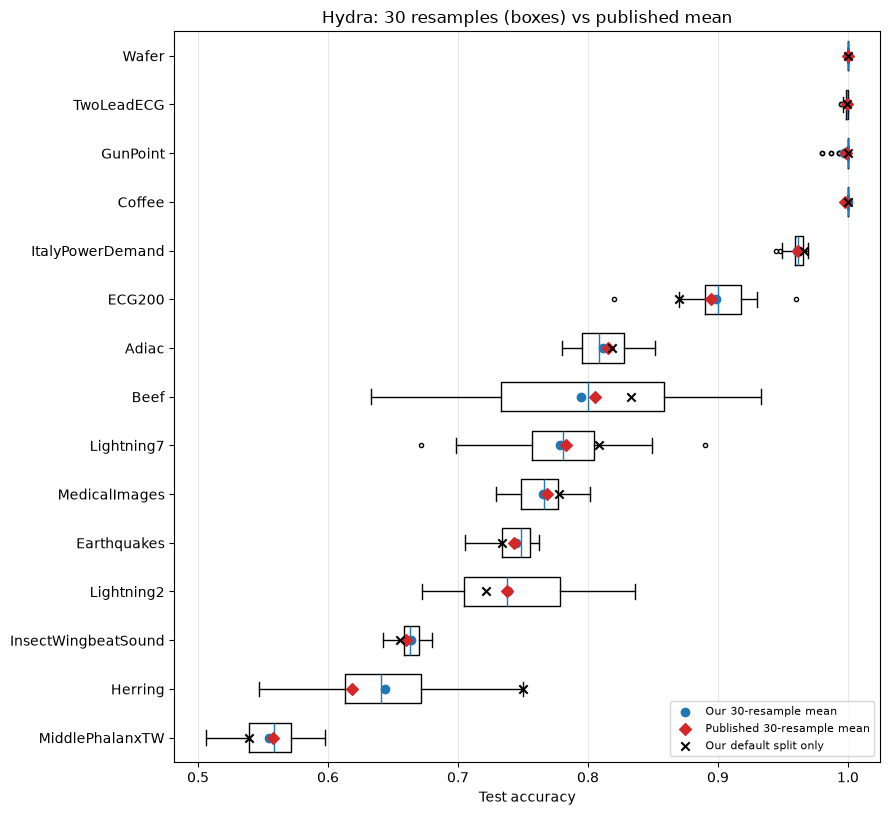

In [9]:
order = summary.sort_values("paper_accuracy")["dataset"].tolist()
fig, ax = plt.subplots(figsize=(9, 0.45 * len(order) + 1.5))

data = [runs.loc[runs["dataset"] == d, "accuracy"].to_numpy() for d in order]
ax.boxplot(data, vert=False, widths=0.6, showfliers=True,
           medianprops={"color": "tab:blue"}, flierprops={"markersize": 3})
positions = np.arange(1, len(order) + 1)
s = summary.set_index("dataset").loc[order]
ax.scatter(s["mean_accuracy"], positions, marker="o", color="tab:blue", zorder=3, label="Our 30-resample mean")
ax.scatter(s["paper_accuracy"], positions, marker="D", color="tab:red", zorder=4, label="Published 30-resample mean")
ax.scatter(s["default_split_accuracy"], positions, marker="x", color="black", zorder=4, label="Our default split only")

ax.set_yticks(positions)
ax.set_yticklabels(order)
ax.set_xlabel("Test accuracy")
ax.set_title("Hydra: 30 resamples (boxes) vs published mean")
ax.ticklabel_format(axis="x", useOffset=False)
ax.grid(True, axis="x", alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(PLOT_DIR / "hydra_resamples_vs_paper.png", dpi=200)
plt.show()

### Cell 10 — Ridge alpha: how often does the chosen value hit the edge of the grid?

The paper does not report the alpha grid; the authors' README uses `np.logspace(-3, 3, 10)` (0.001–1000). If the selected alpha is often at an edge, the grid may be limiting the classifier.

In [10]:
alpha_summary = (
    runs.assign(
        at_upper=np.isclose(runs["ridge_alpha"], PAPER_ALPHAS.max()),
        at_lower=np.isclose(runs["ridge_alpha"], PAPER_ALPHAS.min()),
    )
    .groupby("dataset")
    .agg(pct_alpha_at_upper=("at_upper", "mean"), pct_alpha_at_lower=("at_lower", "mean"), mean_accuracy=("accuracy", "mean"))
    .loc[DATASETS]
)
display((alpha_summary * [100, 100, 1]).round(3).rename(columns={
    "pct_alpha_at_upper": "% runs at alpha=1000", "pct_alpha_at_lower": "% runs at alpha=0.001",
}))
print(f"Overall: {np.isclose(runs['ridge_alpha'], PAPER_ALPHAS.max()).mean():.0%} of runs at the upper bound, "
      f"{np.isclose(runs['ridge_alpha'], PAPER_ALPHAS.min()).mean():.0%} at the lower bound")

,% runs at alpha=1000,% runs at alpha=0.001,mean_accuracy
dataset,,,
Coffee,0.000,100.000,1.000
ECG200,23.333,40.000,0.899
GunPoint,0.000,100.000,0.997
ItalyPowerDemand,10.000,43.333,0.961
TwoLeadECG,0.000,100.000,0.999
Wafer,0.000,0.000,1.000
Herring,93.333,3.333,0.644
MiddlePhalanxTW,100.000,0.000,0.555
Lightning2,46.667,33.333,0.738


Overall: 37% of runs at the upper bound, 37% at the lower bound


### Cell 11 — Run time vs the paper

Both are single-core timings, but on different hardware (paper: Intel Xeon E5-2680 / Gold 6150 cluster), so only the **ratio** is meaningful, and a roughly constant ratio across datasets indicates that the method scales as published.

In [11]:
timing = summary[["dataset", "mean_train_seconds", "paper_train_seconds", "mean_test_seconds", "paper_test_seconds"]].copy()
timing["train_ratio_ours_over_paper"] = timing["mean_train_seconds"] / timing["paper_train_seconds"]
timing["test_ratio_ours_over_paper"] = timing["mean_test_seconds"] / timing["paper_test_seconds"]
display(timing.round(3))
print("Median train-time ratio (ours / paper):", round(timing["train_ratio_ours_over_paper"].median(), 2))
print("Median test-time ratio  (ours / paper):", round(timing["test_ratio_ours_over_paper"].median(), 2))

,dataset,mean_train_seconds,paper_train_seconds,mean_test_seconds,paper_test_seconds,train_ratio_ours_over_paper,test_ratio_ours_over_paper
0,Coffee,0.345,0.320,0.318,0.220,1.076,1.446
1,ECG200,0.333,0.342,0.303,0.192,0.973,1.580
2,GunPoint,0.292,0.281,0.808,0.506,1.036,1.597
3,ItalyPowerDemand,0.047,0.122,0.386,0.310,0.388,1.243
4,TwoLeadECG,0.067,0.122,2.586,1.775,0.548,1.457
5,Wafer,6.949,4.597,34.884,23.544,1.512,1.482
6,Herring,1.293,0.935,1.257,0.839,1.384,1.498
7,MiddlePhalanxTW,1.098,0.790,0.354,0.210,1.390,1.682
8,Lightning2,2.156,1.566,2.160,1.430,1.377,1.511
9,Lightning7,1.049,0.749,1.066,0.669,1.400,1.593


Median train-time ratio (ours / paper): 1.38
Median test-time ratio  (ours / paper): 1.51


## Results and interpretation

**Run:** 15 datasets × 30 resamples = 450 Hydra runs (official code, k = 8, g = 64, `SparseScaler`, README alpha grid, 1 CPU thread).

### 1. The published accuracies reproduce
- **14 of 15 datasets are within expected variance** (|z| ≤ 1.96). The published mean lies inside the range of our 30 resamples for 14 of 15 datasets, and close to our mean in every case (see the plot: each red diamond sits inside the box).
- Across datasets, our 30-resample means differ from the published means by **+0.06 pp on average** (median −0.05 pp, mean absolute difference **0.44 pp**), with 6 datasets higher and 9 lower. The Wilcoxon signed-rank test finds **no systematic difference** (p = 0.64).
- The one flagged dataset, **Herring**, is *above* the paper (+2.55 pp, z = 2.37, two-sided p ≈ 0.018). With 15 datasets tested at the 5% level, about one false flag is expected by chance; after a Holm correction for 15 comparisons (threshold 0.05 / 15 ≈ 0.0033) it is not significant. Herring is also small (64 test cases) and our resamples are not identical to the original tsml splits. We therefore treat it as noise, not a reproduction failure.

**Conclusion:** using the authors' code and settings, Hydra's published UCR accuracies are reproducible; the differences are within the variation expected from resampling and random kernels.

### 2. A single default split is a misleading basis for comparison
With only the default split (the protocol of the earlier baseline notebook), the mean absolute gap to the paper is **1.86 pp**, about **4× larger** than with 30 resamples (0.44 pp). Individual gaps reach **+13.2 pp (Herring)**, +2.8 pp (Beef), +2.5 pp (Lightning7) and **−2.5 pp (ECG200)**. The ECG200 gap seen in the earlier notebook (0.870 vs 0.895) disappears under the paper's protocol (0.899 vs 0.895). Lesson: per-dataset comparisons with published TSC results must use the same resampling protocol; one split cannot separate noise from real differences.

### 3. The ridge alpha grid is often a binding constraint (unreported in the paper)
Over all runs, the selected alpha is at the **upper bound (1000) in 37%** of runs and at the **lower bound (0.001) in 37%**.
- **Upper bound:** almost always on the *harder* datasets: MiddlePhalanxTW, Earthquakes, InsectWingbeatSound (100%), Herring (93%), MedicalImages (57%), Lightning2 (47%). Stronger regularisation than the grid allows might be preferred there.
- **Lower bound:** on easy or tiny datasets (Coffee, GunPoint, TwoLeadECG 100%; Beef 87%), where many alphas tie in leave-one-out cross-validation and scikit-learn keeps the first (smallest). This is a tie-breaking artefact, not a real preference.

Because our accuracies match the paper with this grid, the published results were most likely produced with the same constraint. Whether a wider grid improves accuracy on the harder datasets is a follow-up experiment.

### 4. Run time scales as published
Our single-core training times are a **median 1.38×** and test times **1.51×** the published times, and the ratio is roughly constant across datasets (about 1.0–1.6×; the two smallest datasets are lower because fixed overheads dominate). Our laptop core is simply slower than the paper's cluster cores; the relative cost of Hydra across datasets reproduces.

### Caveats
- `aeon`'s stratified resampling follows the tsml procedure but does not guarantee identical splits, so we compare 30-resample distributions, not individual resamples.
- The z-test assumes the paper's spread across resamples is similar to ours; the published file only gives means, so this cannot be checked directly.
- 15 of the 112 datasets were used; the six project datasets are near 100% accuracy and add little information, which is why nine harder datasets were included.